In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, importlib, time
ROOT = "/content/drive/MyDrive/simuteh-2330511068"
SRC = f"{ROOT}/src"
if SRC not in sys.path:
    sys.path.insert(0, SRC)
importlib.invalidate_caches()
os.chdir(f"{ROOT}/notebook")

import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak
print("OK", os.getcwd())

Mounted at /content/drive
OK /content/drive/MyDrive/simuteh-2330511068/notebook


In [2]:
def konvolusi(img, k):                      # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):               # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"), cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

kernel = {"rerata": np.ones((3, 3)) / 9,
          "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)}
for nm, k in kernel.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")

rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=2.004 s, filter2D=0.00945 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=2.939 s, filter2D=0.00045 s


In [3]:
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):                       # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):             # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}

baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0, kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB", "waktu_ms", "KB"]).round(2)
print(tabel.to_string(index=False))
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)

   derau  penapis  PSNR_dB  waktu_ms   KB
gauss_10    tanpa    28.11      0.00 2.74
gauss_10 rerata_3    36.93      0.32 4.48
gauss_10 rerata_5    38.04      0.50 4.81
gauss_10  gauss_5    37.81      0.90 4.62
gauss_10 median_3    35.49      0.44 4.35
gauss_10 median_5    38.35      2.06 5.05
gauss_10 median_9    38.52     43.69 5.84
gauss_20    tanpa    22.11      0.00 1.58
gauss_20 rerata_3    31.45      0.19 3.54
gauss_20 rerata_5    34.69      0.20 4.31
gauss_20  gauss_5    32.60      0.43 3.80
gauss_20 median_3    29.75      0.13 3.20
gauss_20 median_5    33.50      1.02 4.20
gauss_20 median_9    35.61     22.00 4.94
gauss_40    tanpa    16.41      0.00 0.78
gauss_40 rerata_3    25.86      0.18 2.17
gauss_40 rerata_5    29.86      0.20 3.16
gauss_40  gauss_5    27.08      0.42 2.44
gauss_40 median_3    23.83      0.13 1.81
gauss_40 median_5    27.87      1.02 2.70
gauss_40 median_9    31.44     22.64 3.61
   sp_4%    tanpa    19.28      0.00 1.18
   sp_4% rerata_3    28.49      0.

          PSNR_dB        waktu_ms              KB      
derau    gauss_20  sp_4% gauss_20  sp_4% gauss_20 sp_4%
penapis                                                
tanpa       22.11  19.28     0.00   0.00     1.58  1.18
rerata_3    31.45  28.49     0.19   0.18     3.54  2.99
rerata_5    34.69  31.88     0.20   0.21     4.31  3.93
gauss_5     32.60  29.61     0.43   0.35     3.80  3.27
median_3    29.75  48.17     0.13   0.14     3.20  5.12
median_5    33.50  44.75     1.02   0.99     4.20  5.35
median_9    35.61  40.65    22.00  14.32     4.94  6.20


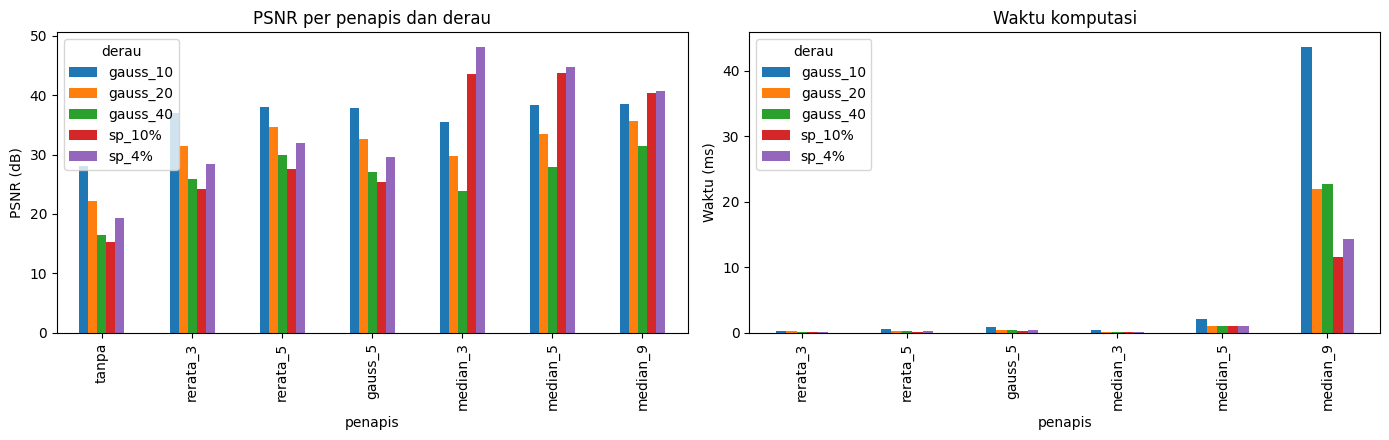

In [4]:
urut = ["tanpa", "rerata_3", "rerata_5", "gauss_5", "median_3", "median_5", "median_9"]
sub = tabel[tabel.derau.isin(["gauss_20", "sp_4%"])]
t11 = sub.pivot(index="penapis", columns="derau", values=["PSNR_dB", "waktu_ms", "KB"]).reindex(urut)
print(t11)
t11.to_csv("../hasil/b4_tabel11.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
tabel.pivot(index="penapis", columns="derau", values="PSNR_dB").reindex(urut).plot.bar(ax=ax[0])
ax[0].set_ylabel("PSNR (dB)"); ax[0].set_title("PSNR per penapis dan derau")
tabel[tabel.penapis != "tanpa"].pivot(index="penapis", columns="derau", values="waktu_ms").reindex(urut[1:]).plot.bar(ax=ax[1])
ax[1].set_ylabel("Waktu (ms)"); ax[1].set_title("Waktu komputasi")
plt.tight_layout(); plt.savefig("../hasil/b4_grafik_psnr_waktu.png", dpi=150); plt.show()

           dI    KB
kernel             
1       27.89  4.44
3       28.09  4.55
5       26.67  4.37
9       19.59  3.67
15       6.44  1.71


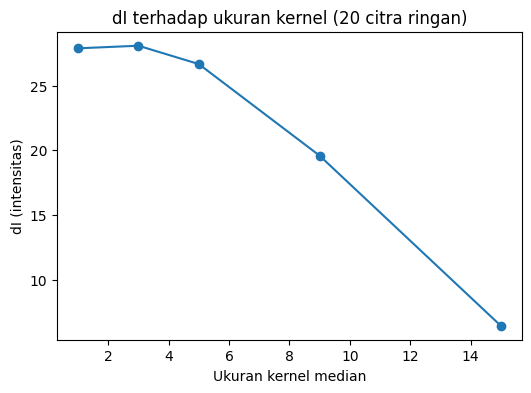

In [5]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:              # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2), kontras_bercak(out, md2, mb2)])

hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
rata = hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2)
print(rata)
rata.to_csv("../hasil/b4_median_bercak.csv")

plt.figure(figsize=(6, 4))
plt.plot(rata.index, rata["dI"], "o-")
plt.xlabel("Ukuran kernel median"); plt.ylabel("dI (intensitas)")
plt.title("dI terhadap ukuran kernel (20 citra ringan)")
plt.savefig("../hasil/b4_di_kernel.png", dpi=150); plt.show()

In [6]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0                              # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))               # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))               # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")

Gaussian: tajam->redam PSNR=30.36 sigma_latar=7.9 | redam->tajam PSNR=30.20 sigma_latar=8.2
Median: tajam->redam PSNR=30.19 sigma_latar=8.1 | redam->tajam PSNR=31.16 sigma_latar=7.2
